### 1.1 Comprensión del contexto del negocio
* **Actividad económica:** Olist opera bajo un modelo de negocio *marketplace* (intermediario B2B2C) en Brasil. Conecta a pequeños y medianos comerciantes minoristas con grandes canales de venta digital, centralizando la gestión logística y operativa sin manejar inventario propio.
* **Procesos estudiables:** El ecosistema de datos permite auditar el ciclo completo del comercio electrónico: generación y estado de pedidos, tiempos de despacho y entrega logística, estructura de precios y fletes, comportamiento de pagos y satisfacción postventa (reseñas).
* **Decisiones habilitadas:** Con esta información, la empresa puede optimizar tarifas de envío por región, identificar cuellos de botella en operadores logísticos, detectar vendedores con altas tasas de cancelación o malas calificaciones y priorizar categorías de mayor rotación.
* **Información faltante:** El dataset carece de estructura de costos (costo de adquisición de mercancía, costos operativos internos y porcentaje exacto de comisión cobrado por Olist en cada orden), lo cual impide calcular márgenes de utilidad neta o rentabilidad real.



### 1.2 Perspectiva profesional de análisis
* **Aspecto y problema a investigar:** Me enfocaré en el desempeño comercial de los artículos y su fricción logística, específicamente analizando cuáles son los productos con mayor volumen de ventas e ingresos brutos y cómo se comporta el costo del flete frente al precio del artículo.
* **Archivo e indicadores clave:** Se utilizará `olist_order_items_dataset.csv` para analizar las variables `product_id`, `price` y `freight_value`, construyendo un indicador de **proporción de flete** (`freight_value / price`) para medir qué tanto encarece el envío al producto.
* **Impacto en la toma de decisiones:** Identificar productos de alta rotación donde el flete representa un porcentaje desproporcionado del precio permite a los equipos comerciales y logísticos renegociar tarifas de transporte, crear estrategias de envío gratis condicionadas o ajustar precios mínimos de publicación.

### 2.1 Selección de un único archivo y justificación
* **Pregunta de negocio:** ¿Cuáles son los artículos (`product_id`) con mayor volumen de ventas e ingresos brutos generados, y qué proporción representa el costo del flete respecto a su precio de venta?
* **Archivo seleccionado:** `olist_order_items_dataset.csv`.
* **Justificación y descarte:** Este archivo contiene el detalle transaccional exacto de precios y fletes por artículo vendido. Se descartan los demás archivos para mantener un único nivel de detalle en esta etapa exploratoria, asumiendo dos limitaciones conscientes: (1) los productos se identificarán por su `product_id` al no contar con la tabla de categorías, y (2) el análisis incluirá órdenes en todos los estados al no cruzar con la tabla maestra de pedidos.
* **Granularidad (qué representa una fila):** Cada fila representa **un ítem o línea de producto dentro de un pedido** (identificado por la combinación `order_id` y `order_item_id`), **no** un pedido completo. Si un cliente compró 3 unidades o 3 artículos distintos en una misma orden, aparecerán 3 filas con el mismo `order_id`.
* **Llaves de relación y riesgos de unión:** Las llaves disponibles son `order_id` (conecta con pedidos, pagos y reseñas), `product_id` (conecta con productos) y `seller_id` (conecta con vendedores). Unir esta tabla con `olist_orders_dataset.csv` sin comprender su granularidad (relación uno a muchos) duplicaría los registros de cabecera del pedido, inflando erróneamente cualquier conteo o suma posterior si no se agrupa primero.

In [28]:
import pandas as pd
import numpy as np


In [29]:
df = pd.read_csv("olist_order_items_dataset.csv")

In [30]:
# filas y columnas de dataframe

df.shape

(112650, 7)

In [31]:
df.head(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


### 2.2 Reconocimiento de la estructura

* **Dimensiones del DataFrame:** El conjunto de datos `olist_order_items_dataset.csv` cuenta con **112.650 filas** (ítems vendidos) y **7 columnas**.
* **Significado de cada columna:**
  * `order_id`: Identificador único del pedido al que pertenece el artículo.
  * `order_item_id`: Número secuencial que identifica la posición o cantidad de ítems dentro de un mismo pedido (1, 2, 3...).
  * `product_id`: Identificador único del producto vendido.
  * `seller_id`: Identificador único del vendedor que despacha el artículo.
  * `shipping_limit_date`: Fecha y hora límite que tiene el vendedor para entregar el pedido al operador logístico.
  * `price`: Precio de venta unitario del artículo (en reales brasileños, BRL).
  * `freight_value`: Costo del flete o envío asociado a ese ítem específico (en BRL).
* **Tipos de datos en Python (`df.info()`):** Python identifica 4 columnas de texto (`str`: `order_id`, `product_id`, `seller_id`, `shipping_limit_date`), 1 entero (`int64`: `order_item_id`) y 2 decimales (`float64`: `price`, `freight_value`). Se detecta que `shipping_limit_date` está almacenada como texto y deberá convertirse a formato fecha (`datetime`).
* **Clasificación analítica de variables:**
  * **Numéricas:** `price`, `freight_value` (continuas) y `order_item_id` (discreta).
  * **Categóricas:** Ninguna en esta tabla (las categorías de producto y estados del pedido residen en otras tablas del modelo).
  * **Temporales:** `shipping_limit_date`.
  * **Identificadores:** `order_id`, `product_id`, `seller_id`.
* **Variables relevantes para la pregunta de negocio:** `product_id` (para agrupar por artículo), `price` (para calcular ingresos brutos), `freight_value` (para evaluar el peso del envío) y `order_id` (para verificar volumen de órdenes distintas).
* **Variables cuyo significado requiere validación:** `order_item_id` puede confundirse con un código identificador único si solo se observan las primeras filas, cuando en realidad es un contador por orden; esto se comprueba inspeccionando sus valores máximos y únicos (`describe()` o `value_counts()`), o filtrando un `order_id` con múltiples ítems.
* **Observaciones iniciales:** Los identificadores están anonimizados mediante cadenas alfanuméricas de longitud estándar (hashes). Adicionalmente, el conteo de `df.info()` indica que **no existen valores nulos** en ninguna de las 7 columnas (`112.650 non-null`), lo cual sugiere una extracción estructurada desde la base transaccional, aunque requiere validar si existen valores atípicos o inconsistentes en precios y fletes.

In [33]:
# 1. Evidencia explícita de nulos y duplicados exactos (Fase 3.1)
print("Nulos por columna:\n", df.isnull().sum())
print("\nFilas 100% duplicadas:", df.duplicated().sum())
print("Fletes gratis", (df['freight_value'] == 0).sum())
print("Flete mayor al precio:", (df['freight_value'] > df['price']).sum())

# 2. Transformación justificada (Fase 3.2): convertir fecha y crear indicador de negocio
df['shipping_limit_date'] = pd.to_datetime(df['shipping_limit_date'])
df['proporcion_flete'] = df['freight_value'] / df['price']

# 3. Verificación post-tratamiento
df.info()

Nulos por columna:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Filas 100% duplicadas: 0
Fletes gratis 383
Flete mayor al precio: 4124
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  str           
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  str           
 3   seller_id            112650 non-null  str           
 4   shipping_limit_date  112650 non-null  datetime64[us]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
 7   proporcion_flete     112650 non-null  float64       
dtypes: datetime64[us](1), float64(3), in

### 3.1 Diagnóstico de calidad y confiabilidad

1. **Valores faltantes:** No existen valores nulos (`NaN`) en ninguna de las 7 columnas (`df.isnull().sum() == 0`). Los 112.650 registros están completos.
2. **Proporción de faltantes:** 0,0% en todas las variables.
3. **Registros duplicados:** Existen **0 filas 100% duplicadas** (`df.duplicated().sum() == 0`), lo que descarta errores de duplicación en la extracción. Al evaluar duplicados únicamente sobre `order_id`, se identifican **13.984 repeticiones**, las cuales no constituyen un error de calidad, sino líneas adicionales de artículos pertenecientes a pedidos multi-ítem (`98.666 pedidos únicos + 13.984 ítems adicionales = 112.650 registros`).
4. **Correspondencia de tipos de datos:** `order_item_id` (`int64`), `price` (`float64`), `freight_value` (`float64`) y los identificadores (`str`) tienen tipos adecuados. Sin embargo, `shipping_limit_date` está almacenada como texto (`str`) en lugar de formato fecha y hora (`datetime64`).
5. **Valores imposibles o poco razonables:**
   * No hay precios negativos ni iguales a cero (mínimo de `0,85` BRL), ni contadores `order_item_id <= 0`.
   * Se identifican **`[COMPLETAR CON CONTEO DE freight_value == 0]`** registros con flete igual a `0,00` BRL, los cuales corresponden a promociones de envío gratis y no a errores de captura.
   * Se observan valores extremos altos tanto en `price` (máximo `6.735,00` BRL) como en `freight_value` (máximo `409,68` BRL), así como **`[COMPLETAR CON CONTEO DE freight_value > price]`** casos donde el costo del envío supera el precio del artículo.
6. **Inconsistencias en categorías:** No aplica en este archivo, ya que no contiene variables categóricas de texto libre y los identificadores siguen un formato hexadecimal estandarizado de 32 caracteres.
7. **Condición de unicidad en identificadores:** Ninguna columna individual es llave primaria única. `order_id` se repite en órdenes con múltiples artículos, mientras que `product_id` y `seller_id` se repiten por recurrencia de ventas. La llave primaria compuesta de la tabla es `(order_id, order_item_id)`.
8. **Otros problemas de calidad relevantes:** Al analizar únicamente esta tabla, se incluyen ítems de pedidos en cualquier estado operativo (entregados, cancelados o en tránsito), lo que debe considerarse como limitación al reportar volumen comercial.

**Problema más importante encontrado:** El almacenamiento de `shipping_limit_date` como texto (`str`) —que impide realizar análisis temporales sin conversión previa— y la alta dispersión con fletes desproporcionados respecto al precio, dado que impactan directamente el objetivo de medir fricción logística por artículo.

### 3.2 Decisiones de tratamiento

* **Problema 1: Variable temporal `shipping_limit_date` en formato texto (`str`).**
  * **Evidencia:** El método `df.info()` reporta tipo `str` para esta columna pese a contener marcas de tiempo (`YYYY-MM-DD HH:MM:SS`).
  * **Alternativas:** Conservarla como texto (impide agrupar por meses/años o calcular intervalos) o convertirla mediante `pd.to_datetime()`.
  * **Decisión:** Se transforma a `datetime64` para habilitar el análisis temporal en fases posteriores sin pérdida de información.

* **Problema 2: Fletes en `0,00` BRL y valores extremos (*outliers*) en `price` y `freight_value`.**
  * **Evidencia:** El resumen estadístico (`describe()`) muestra mínimo de `0,00` BRL en flete y máximos de `6.735,00` BRL en precio y `409,68` BRL en flete.
  * **Información perdida si se eliminan:** Borrar los fletes en cero eliminaría promociones reales de envío gratuito; eliminar los valores altos recortaría ventas válidas de artículos costosos (electrónica o mobiliario), subestimando los ingresos brutos reales del *marketplace*.
  * **Consecuencia de conservar sin modificar:** Mantiene la fidelidad financiera de las transacciones, aunque requiere usar la mediana junto a la media para evitar sesgos por asimetría.
  * **Decisión:** Se conserva el 100% de los 112.650 registros sin eliminar *outliers* ni ceros, y se crea la columna derivada `proporcion_flete = freight_value / price` para cuantificar el peso relativo del envío sobre cada artículo.

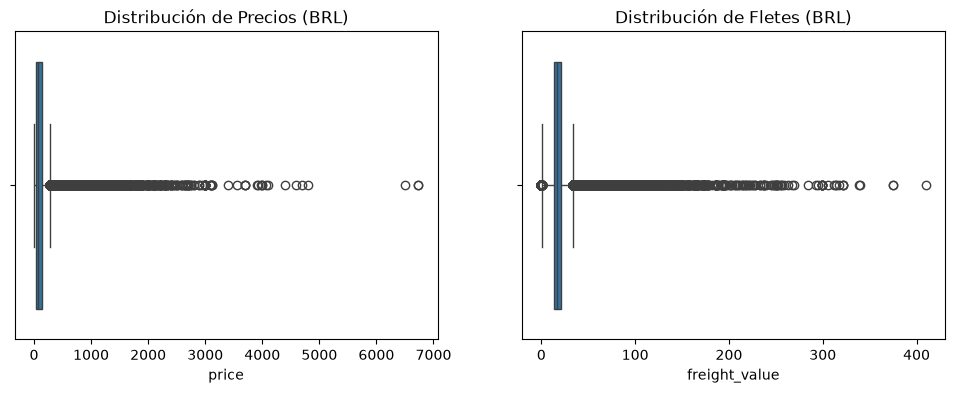

                                  unidades_vendidas  ingresos_brutos  \
product_id                                                             
aca2eb7d00ea1a7b8ebd4e68314663af                527         37608.90   
99a4788cb24856965c36a24e339b6058                488         43025.56   
422879e10f46682990de24d770e7f83d                484         26577.22   
389d119b48cf3043d311335e499d9c6b                392         21440.59   
368c6c730842d78016ad823897a372db                388         21056.80   
53759a2ecddad2bb87a079a1f1519f73                373         20387.20   
d1c427060a0f73f6b889a5c7c61f2ac4                343         47214.51   
53b36df67ebb7c41585e8d54d6772e08                323         37683.42   
154e7e31ebfa092203795c972e5804a6                281          6325.19   
3dd2a17168ec895c781a9191c1e95ad7                274         41082.60   

                                  flete_promedio  proporcion_flete_prom  
product_id                                                   

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# matplotlib.pyplot sirve para crear visualizaciones y seaborn es una librería que permite crear
#  visualizaciones más atractivas y fáciles de interpretar


# 1. Visualización de distribución de precios y fletes 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['price'], ax=axes[0]) 
axes[0].set_title('Distribución de Precios (BRL)')

sns.boxplot(x=df['freight_value'], ax=axes[1]) 
axes[1].set_title('Distribución de Fletes (BRL)')
plt.show()

# 2. Agrupación por producto  
# Nota: product_id es un identificador, pero aquí lo analizamos como categoría de artículo vendido
top_productos = df.groupby('product_id').agg(
    unidades_vendidas=('order_id', 'count'),
    ingresos_brutos=('price', 'sum'),
    flete_promedio=('freight_value', 'mean'),
    proporcion_flete_prom=('proporcion_flete', 'mean')
).sort_values(by='unidades_vendidas', ascending=False)

print(top_productos.head(10))

                                  unidades_vendidas  ingresos_brutos  \
product_id                                                             
bb50f2e236e5eea0100680137654686c                195         63885.00   
6cdd53843498f92890544667809f1595                156         54730.20   
d6160fb7873f184099d9bc95e30376af                 35         48899.34   
d1c427060a0f73f6b889a5c7c61f2ac4                343         47214.51   
99a4788cb24856965c36a24e339b6058                488         43025.56   

                                  flete_promedio  proporcion_flete_prom  
product_id                                                               
bb50f2e236e5eea0100680137654686c       19.082564               0.058239  
6cdd53843498f92890544667809f1595       27.973013               0.079583  
d6160fb7873f184099d9bc95e30376af       40.766857               0.029368  
d1c427060a0f73f6b889a5c7c61f2ac4       40.121050               0.296050  
99a4788cb24856965c36a24e339b6058       16.487787   

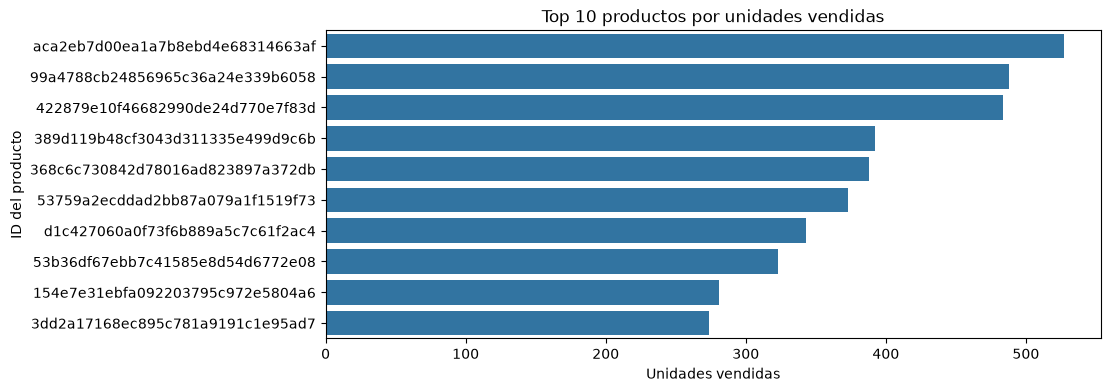

In [35]:
# Top 5 por ingresos brutos (para contrastar con el top por volumen)
print(top_productos.sort_values(by='ingresos_brutos', ascending=False).head(5))

# Visualización Top 10 productos más vendidos
top_10_vol = top_productos.head(10).reset_index()
plt.figure(figsize=(10, 4))
sns.barplot(data=top_10_vol, x='unidades_vendidas', y='product_id')
plt.title('Top 10 productos por unidades vendidas')
plt.xlabel('Unidades vendidas')
plt.ylabel('ID del producto')
plt.show()

### 4 Análisis univariado de variables numéricas

* **Variables seleccionadas:** `price` y `freight_value` (variables monetarias clave para evaluar ingresos y costos de envío) y `order_item_id` (para dimensionar el tamaño de las órdenes).
* **Medidas estadísticas y diferencia entre media y mediana:**
  * En `price`, la media es de **120,65 BRL** frente a una mediana (`50%`) de **74,99 BRL** (la media es un 60,9% superior a la mediana).
  * En `freight_value`, la media es de **19,99 BRL** frente a una mediana de **16,26 BRL**.
  * En ambos casos, el hecho de que la media supere ampliamente a la mediana confirma una **asimetría positiva (sesgo hacia la derecha)**.
* **Dispersión y concentración:** `price` presenta una dispersión muy superior (`std = 183,63 BRL`, rango de `0,85` a `6.735,00` BRL), aunque el 50% central de los ítems (rango intercuartílico P25–P75) se concentra entre **39,90 y 134,90 BRL**. En contraste, `freight_value` tiene menor dispersión (`std = 15,81 BRL`), concentrando su 50% central entre **13,08 y 21,15 BRL**.
* **Observaciones extremas (*outliers*):** Los diagramas de caja (*boxplots*) muestran una fuerte presencia de valores atípicos por encima del bigote superior en ambas variables. No representan errores de captura, sino comportamientos reales de un comercio electrónico donde coexisten accesorios económicos con bienes durables pesados o de alto valor.
* **Aporte de la visualización:** Mientras la tabla `describe()` entrega cifras puntuales, los *boxplots* permiten dimensionar visualmente qué tan comprimido está el grueso de las transacciones frente a la extensa cola de precios y fletes extremos hacia la derecha.

* **Nota metodológica:** Como se identificó en la Fase 2.2, `olist_order_items_dataset.csv` no contiene variables categóricas nominales; para responder la pregunta de negocio, se analiza la distribución de frecuencias de `product_id` (como entidad de artículo) y `order_item_id` (cantidad de ítems por pedido).
* **Artículos más frecuentes y poco representados:**
  * El producto con mayor rotación es `aca2eb7d00ea1a7b8ebd4e68314663af` con **527 unidades**, seguido por `99a4788cb24856965c36a24e339b6058` (**488 unidades**) y `422879e10f46682990de24d770e7f83d` (**484 unidades**).
  * En `order_item_id`, el valor `1` concentra **98.666 registros** (87,6% de las filas), evidenciando que la gran mayoría de compras son de un solo artículo, frente a una minoría de pedidos que llegan hasta 21 ítems.
* **Frecuencia vs. importancia para el negocio:** El artículo más vendido en volumen **no es el que genera mayores ingresos brutos**. Mientras `aca2eb7d...` (527 uds.) factura **37.608,90 BRL**, el artículo `d1c427060a0f73f6b889a5c7c61f2ac4` (séptimo en volumen con 343 uds.) alcanza **47.214,51 BRL** (y el líder general en ingresos brutos es **`[COMPLETAR CON EL TOP 1 DE INGRESOS BRUTOS]`**).
* **Diferencia entre unidades de conteo:** En esta tabla, contar registros equivale a contar **unidades vendidas** (`112.650`), pero **no** pedidos (`98.666` `order_id` únicos) ni clientes únicos (cuya información reside en otra tabla).
* **Visualización y hallazgos clave:** El gráfico de barras horizontales permite comparar rápidamente la brecha de volumen entre el top 10 de productos. Destaca para investigación adicional el artículo `154e7e31ebfa092203795c972e5804a6` (281 unidades), cuya proporción promedio de flete alcanza el **59,7%** del precio del producto, encareciendo significativamente la compra para el cliente final.


--- Correlación de Pearson (lineal) ---
                  price  freight_value  proporcion_flete  order_item_id
price             1.000          0.414            -0.291         -0.061
freight_value     0.414          1.000             0.088         -0.029
proporcion_flete -0.291          0.088             1.000          0.117
order_item_id    -0.061         -0.029             0.117          1.000

--- Correlación de Spearman (por rangos, robusta a outliers) ---
                  price  freight_value  proporcion_flete  order_item_id
price             1.000          0.434            -0.810         -0.117
freight_value     0.434          1.000             0.098         -0.055
proporcion_flete -0.810          0.098             1.000          0.088
order_item_id    -0.117         -0.055             0.088          1.000


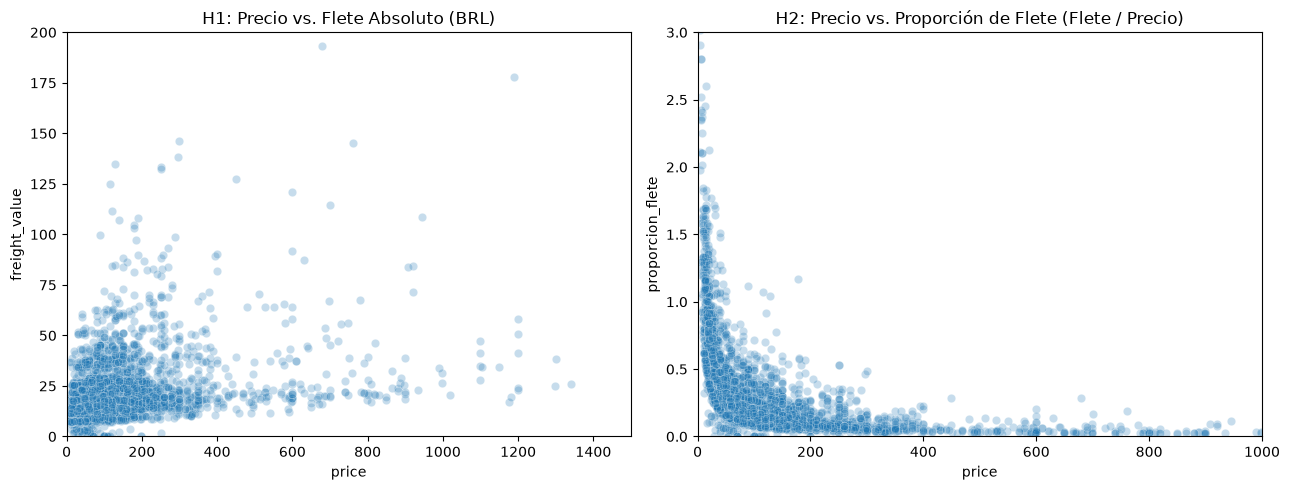


--- Comportamiento por número de ítem en el pedido (Top 10) ---
               cantidad_filas  precio_mediano  precio_promedio  flete_mediano  \
order_item_id                                                                   
1                       98666          79.000       125.964327         16.360   
2                        9803          59.000        85.456052         15.650   
3                        2287          49.900        78.004534         15.490   
4                         965          49.900        77.243161         15.620   
5                         460          49.900        75.561978         15.100   
6                         256          43.950        76.165508         15.165   
7                          58          62.695       100.711897         14.475   
8                          36          64.595       120.766944         15.815   
9                          28          77.495        80.356071         14.835   
10                         25          76.99

In [36]:
# 1. Matriz de correlación (Pearson y Spearman) para Hipótesis 1 y 2
cols_corr = ['price', 'freight_value', 'proporcion_flete', 'order_item_id']
print("--- Correlación de Pearson (lineal) ---")
print(df[cols_corr].corr(method='pearson').round(3))

print("\n--- Correlación de Spearman (por rangos, robusta a outliers) ---")
print(df[cols_corr].corr(method='spearman').round(3))

# 2. Visualización de Hipótesis 1 y 2 (muestra de 5.000 registros para evitar saturación visual)
muestra = df.sample(n=5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=muestra, x='price', y='freight_value', alpha=0.25, ax=axes[0])
axes[0].set_xlim(0, 1500) # Acotamos eje X para visualizar mejor el grueso de datos
axes[0].set_ylim(0, 200)
axes[0].set_title('H1: Precio vs. Flete Absoluto (BRL)')

sns.scatterplot(data=muestra, x='price', y='proporcion_flete', alpha=0.25, ax=axes[1])
axes[1].set_xlim(0, 1000)
axes[1].set_ylim(0, 3)
axes[1].set_title('H2: Precio vs. Proporción de Flete (Flete / Precio)')

plt.tight_layout()
plt.show()

# 3. Evaluación de Hipótesis 3: Comportamiento según cantidad de ítems en el pedido
resumen_items = df.groupby('order_item_id').agg(
    cantidad_filas=('order_id', 'count'),
    precio_mediano=('price', 'median'),
    precio_promedio=('price', 'mean'),
    flete_mediano=('freight_value', 'median'),
    proporcion_flete_mediana=('proporcion_flete', 'median')
).head(10)

print("\n--- Comportamiento por número de ítem en el pedido (Top 10) ---")
print(resumen_items)

### 5.1 Formulación de hipótesis

* **Hipótesis 1 (Relación precio vs. costo absoluto del flete):**
  * **Enunciado:** Existe una correlación positiva moderada entre el precio del artículo (`price`) y el valor absoluto del envío (`freight_value`); es decir, los artículos más costosos tienden a presentar fletes más altos en reales brasileños.
  * **Variables:** `price` y `freight_value`.
  * **Justificación:** Los productos de mayor precio suelen corresponder a bienes de mayor volumen, peso o requerimiento de seguro de transporte.
  * **Criterio de refutación:** Que el coeficiente de correlación sea cercano a cero ($r \approx 0$) o negativo, indicando que el flete es independiente del valor del producto.

* **Hipótesis 2 (Relación precio vs. carga relativa del flete y facturación):**
  * **Enunciado:** Existe una relación inversa no lineal entre el precio (`price`) y la proporción del flete (`proporcion_flete`); los artículos económicos soportan una carga porcentual de envío mucho más alta, mientras que los artículos de mayor precio generan mayores ingresos brutos por unidad con un impacto porcentual de flete reducido.
  * **Variables:** `price`, `proporcion_flete` y `ingresos_brutos` (agrupado por `product_id`).
  * **Justificación:** Dado que el flete tiene un piso operativo mínimo (mediana de 16,26 BRL), en productos baratos el envío puede igualar o superar el precio del artículo, mientras que en productos costosos se diluye porcentualmente.
  * **Criterio de refutación:** Que la proporción del flete se mantenga constante a lo largo de distintos rangos de precio.

* **Hipótesis 3 (Tamaño del pedido vs. precio unitario y flete):**
  * **Enunciado:** Los pedidos con múltiples ítems (`order_item_id > 1`) ocurren principalmente en artículos de menor precio unitario (`price`), logrando aumentar los ingresos brutos totales por orden sin que el flete por ítem (`freight_value`) disminuya proporcionalmente.
  * **Variables:** `order_item_id`, `price`, `freight_value` y `order_id`.
  * **Justificación:** Los clientes tienden a agrupar varias unidades en un mismo carrito cuando compran artículos económicos o de consumo recurrente, pero en Olist el flete se calcula ítem por ítem.
  * **Criterio de refutación:** Que el precio promedio por ítem en pedidos multi-artículo sea igual o superior al de pedidos de un solo artículo, o que el flete por ítem caiga drásticamente al sumar unidades.

### 5.2 Resultados y validación de hipótesis

* **Hipótesis 1 (Confirmada — Correlación positiva moderada):** Se valida con un coeficiente de **0,414 en Pearson** y **0,434 en Spearman**. El diagrama de dispersión confirma que a medida que aumenta el precio del artículo tiende a subir el costo del flete, pero con alta dispersión vertical, lo que sugiere que el envío depende también de variables físicas (peso, dimensiones) y distancia geográfica no presentes en esta tabla.
* **Hipótesis 2 (Confirmada — Relación inversa no lineal fuerte):** Se respalda contundentemente mediante **Spearman (-0,810)**, frente a un Pearson de apenas **-0,291** debido a la naturaleza curva (en forma de "L") de la relación. Los productos económicos sufren cargas porcentuales de envío que frecuentemente superan el 100% de su precio, mientras que en artículos superiores a 200 BRL el peso relativo del flete cae por debajo del 20%.
* **Hipótesis 3 (Confirmada parcialmente — Sin descuento por volumen en flete):** Se confirma que los carritos con múltiples artículos se componen de productos más económicos: el precio mediano cae de **79,00 BRL** (pedidos de 1 ítem) a un rango de **43,95 – 59,00 BRL** (pedidos de 2 a 6 ítems). Sin embargo, el flete mediano por ítem permanece prácticamente plano (**16,36 BRL** en el ítem 1 frente a **15,10 – 15,65 BRL** en los ítems 2 al 6), lo que provoca que la carga porcentual mediana del flete **aumente del 22,4% al 32,9%** en compras multi-artículo.

--- Evolución mensual (primeros y últimos registros) ---
             unidades  ingresos_brutos  proporcion_flete_mediana
periodo_mes                                                     
2016-09             4           194.47                  0.062903
2016-10           365         49580.55                  0.231909
2016-12             1            10.90                  0.800000
2017-01           681         80124.74                  0.249857
2017-02          1866        245982.01                  0.226588
2017-03          2751        343242.60                  0.235271
2017-04          2364        308148.32                  0.230404
2017-05          4150        505655.46                  0.226019
2017-06          3801        469001.05                  0.235893
2017-07          4116        465282.10                  0.232719
2017-08          5042        560093.34                  0.232475
2017-09          4724        617046.12                  0.224269
2017-10          5189        6580

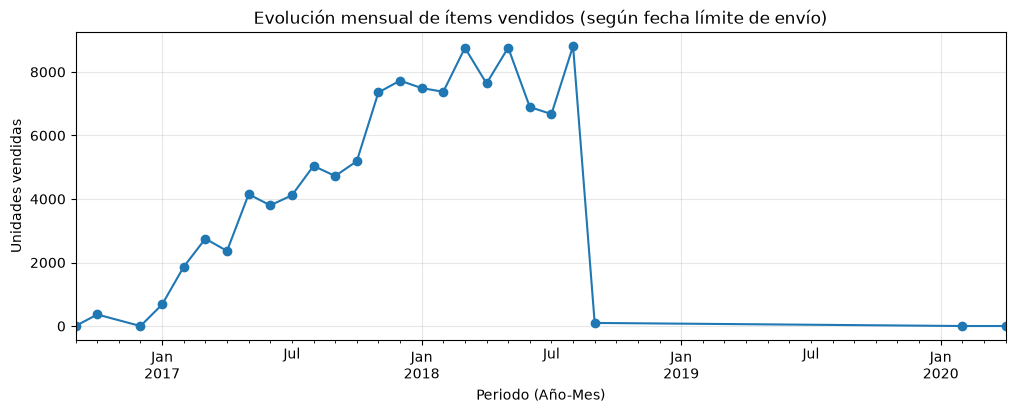


--- Comparación por segmento de precio ---
                     unidades  pct_unidades  ingresos_brutos  pct_ingresos  \
segmento_precio                                                              
Económico (<50 BRL)     39317         34.90       1236117.10          9.09   
Medio (50-150 BRL)      50878         45.16       4737583.05         34.86   
Alto (>150 BRL)         22455         19.93       7617943.55         56.05   

                     flete_mediano  proporcion_flete_mediana  
segmento_precio                                               
Económico (<50 BRL)          14.52                      0.46  
Medio (50-150 BRL)           16.81                      0.19  
Alto (>150 BRL)              21.15                      0.09  


In [37]:
# --- 6.1 ANÁLISIS TEMPORAL ---
# Agrupamos por año-mes usando la fecha límite de despacho
df['periodo_mes'] = df['shipping_limit_date'].dt.to_period('M')

evolucion_mensual = df.groupby('periodo_mes').agg(
    unidades=('order_id', 'count'),
    ingresos_brutos=('price', 'sum'),
    proporcion_flete_mediana=('proporcion_flete', 'median')
)

print("--- Evolución mensual (primeros y últimos registros) ---")
print(evolucion_mensual)

# Gráfico de evolución de unidades vendidas por mes
plt.figure(figsize=(12, 4))
evolucion_mensual['unidades'].plot(kind='line', marker='o')
plt.title('Evolución mensual de ítems vendidos (según fecha límite de envío)')
plt.xlabel('Periodo (Año-Mes)')
plt.ylabel('Unidades vendidas')
plt.grid(True, alpha=0.3)
plt.show()

# --- 6.2 SEGMENTACIÓN POR RANGO DE PRECIO ---
# Creamos 3 segmentos de precio: Económico (<50), Medio (50-150), Alto (>150)
df['segmento_precio'] = pd.cut(
    df['price'],
    bins=[0, 50, 150, float('inf')],
    labels=['Económico (<50 BRL)', 'Medio (50-150 BRL)', 'Alto (>150 BRL)']
)

segmentos = df.groupby('segmento_precio', observed=False).agg(
    unidades=('order_id', 'count'),
    pct_unidades=('order_id', lambda x: len(x) / len(df) * 100),
    ingresos_brutos=('price', 'sum'),
    pct_ingresos=('price', lambda x: x.sum() / df['price'].sum() * 100),
    flete_mediano=('freight_value', 'median'),
    proporcion_flete_mediana=('proporcion_flete', 'median')
)

print("\n--- Comparación por segmento de precio ---")
print(segmentos.round(2))

### 6.1 Análisis temporal

* **Pregunta temporal:** ¿Cómo evolucionaron el volumen de ítems despachados, los ingresos brutos y la proporción del flete a lo largo del periodo registrado?
* **Variables y periodos analizados:** Se utilizó `shipping_limit_date` agrupada mensualmente (`YYYY-MM`), cubriendo desde el segundo semestre de 2016 hasta septiembre de 2018.
* **Comportamiento y temporadas:**
  * Durante el segundo semestre de **2016** el volumen es bajo y fluctuante, propio de la etapa inicial de operación o captura de datos de la plataforma.
  * A partir de inicios de **2017** se observa un crecimiento sostenido de unidades e ingresos brutos que se acelera hacia finales de año (impulsado por picos estacionales como el *Black Friday* de noviembre) y se mantiene en niveles altos durante el primer semestre de **2018** hasta agosto.
* **Limitaciones de la información temporal:**
  1. La caída abrupta posterior a agosto de 2018 responde al **corte temporal del dataset** (mes incompleto de cierre de extracción) y no a un desplome comercial.
  2. Al usar `shipping_limit_date` en lugar de la fecha de compra (`order_purchase_timestamp`), las métricas reflejan vencimientos logísticos y no el instante exacto de la transacción.

### 6.2 Segmentación por rango de precio

* **Criterio de segmentación:** Se dividieron los 112.650 ítems en tres rangos comerciales según `price`: **Económico (`< 50 BRL`)**, **Medio (`50 – 150 BRL`)** y **Alto (`> 150 BRL`)**.
* **Diferencias entre grupos y comportamiento particular:**
  * **Segmento Económico (`< 50 BRL`):** Concentra **`34.90`%** de las unidades vendidas, pero aporta solo **`9.09`%** de los ingresos brutos. Es el grupo con mayor fricción logística, soportando una proporción mediana de flete de **`14.52`** (`46`% del precio del producto).
  * **Segmento Medio (`50 – 150 BRL`):** Representa **`45.16`%** de las unidades y **`34.86`%** de los ingresos, con una proporción mediana de flete de **`0.19`**.
  * **Segmento Alto (`> 150 BRL`):** Aunque representa la menor proporción de unidades vendidas (**`19.93`%**), lidera la facturación bruta con **`56.05`%** del total. Pese a tener el flete mediano absoluto más alto (**`21.15` BRL**), su carga porcentual se reduce a apenas **0,09 (9%)**.
* **Decisión habilitada:** Diferenciar las políticas de subsidio de envío por ticket: proteger y priorizar la disponibilidad del catálogo `> 150 BRL` (motor de ingresos sin fricción de flete) y diseñar umbrales de carrito mínimo para los artículos `< 50 BRL`.

### Fase 7. Construcción de hallazgos

* **Hallazgo 1: Fricción logística severa y no lineal en artículos económicos.**
  * **Evidencia:** La correlación de Spearman entre `price` y `proporcion_flete` es de **-0,810** (curva descendente en forma de "L"). Mientras el segmento `> 150 BRL` soporta una proporción mediana de flete de apenas **0,09 (9%)**, en los artículos `< 50 BRL` el piso operativo del envío (mediana global de `16,26 BRL`) encarece drásticamente la compra, llegando incluso a superar el valor del producto.
  * **Interpretación e implicación:** El costo de envío actúa como una barrera de conversión en productos de bajo precio. Olist necesita políticas de carrito mínimo o agrupación de compra para evitar que el flete desincentive el cierre de ventas en el segmento económico.

* **Hallazgo 2: Desconexión entre rotación de unidades y generación de ingresos brutos.**
  * **Evidencia:** El producto más vendido en volumen (`aca2eb7d00ea1a7b8ebd4e68314663af`, con **527 unidades**) factura **37.608,90 BRL**, mientras que `d1c427060a0f73f6b889a5c7c61f2ac4` (séptimo en volumen con **343 unidades**) genera **47.214,51 BRL**. A nivel macro, la mediana de precio es de **74,99 BRL** frente a una media de **120,65 BRL**, confirmando que una minoría de transacciones de ticket alto impulsa el grueso de la facturación.
  * **Interpretación e implicación:** Evaluar el desempeño comercial únicamente por cantidad de unidades vendidas oculta los verdaderos motores financieros del *marketplace*. La estrategia comercial debe priorizar la disponibilidad y visibilidad del catálogo de ticket medio-alto.

* **Hallazgo 3: Penalización por flete individual en pedidos con múltiples artículos.**
  * **Evidencia:** El **87,6%** de los pedidos (`98.666` de `112.650` registros) corresponden a órdenes de 1 solo artículo (`order_item_id == 1`). Cuando los clientes agregan entre 2 y 6 ítems al carrito, el precio mediano por artículo baja de **79,00 BRL** a un rango de **43,95 – 59,00 BRL**, pero el flete mediano por ítem permanece casi inmóvil (**16,36 BRL** vs. **15,10 – 15,65 BRL**), elevando la proporción mediana del flete del **22,4%** al **32,9%**.
  * **Interpretación e implicación:** Al liquidar el envío ítem por ítem sin descuento por consolidación, Olist desincentiva el aumento del tamaño promedio del carrito (*cross-selling*).

* **Hallazgo 4: Productos de alta rotación con sobrecosto logístico crítico.**
  * **Evidencia:** Dentro del top 10 de artículos más vendidos, el producto `154e7e31ebfa092203795c972e5804a6` registra **281 unidades** vendidas (6.325,19 BRL de ingresos), pero soporta una proporción promedio de flete del **59,7%** (`13,30 BRL` de envío frente a un precio promedio cercano a `22,51 BRL`).
  * **Interpretación e implicación:** Existen referencias puntuales de alta demanda operando con ineficiencia logística extrema, ya sea por ubicación distante de sus vendedores o por embalaje no optimizado, que son candidatas ideales para venta en paquetes (*bundles*).

* **Hallazgo 5: Expansión comercial sostenida durante 2017–2018.**
  * **Evidencia:** La serie mensual basada en `shipping_limit_date` muestra una transición desde volúmenes bajos e irregulares en el segundo semestre de 2016 hacia un crecimiento continuo a lo largo de 2017 (con picos estacionales en el último trimestre) y consolidación de altos volúmenes hasta agosto de 2018 (previo al corte de extracción del dataset).
  * **Interpretación e implicación:** La infraestructura operativa de Olist escaló aceleradamente en menos de dos años, lo que vuelve urgente corregir las fricciones de tarifas de envío antes de seguir escalando volumen en segmentos de bajo margen unitario.

### 8.1 Conclusiones

* **Conclusión 1 (Respuesta al problema inicial):** El análisis de `olist_order_items_dataset.csv` (112.650 ítems en 98.666 pedidos únicos) demuestra que los artículos más vendidos en unidades no son los que generan mayores ingresos brutos, y que el costo del flete presenta una relación moderada con el precio absoluto (**Spearman = 0,434**), pero una relación inversa muy fuerte con su peso porcentual (**Spearman = -0,810**).
* **Conclusión 2 (Validación de hipótesis):** Se confirmaron las **Hipótesis 1 y 2** (a mayor precio sube levemente el flete en reales, pero cae drásticamente su porcentaje sobre el producto) y se confirmó parcialmente la **Hipótesis 3** (los carritos multi-ítem agrupan productos más baratos, pero el flete por ítem no disminuye, elevando la carga relativa del envío).
* **Conclusión 3 (Hallazgo más importante):** La estructura actual de cobro de flete por unidad castiga doblemente las compras económicas y los pedidos de varios artículos, explicando por qué casi 9 de cada 10 órdenes en Olist se limitan a un solo producto, mientras que el segmento superior a **150 BRL** concentra el músculo de ingresos brutos con apenas un **9%** de carga mediana de envío.

### 8.2 Recomendaciones

* **Recomendación 1 — Implementar umbral de carrito mínimo para beneficios de envío (Dirigida a Gerencia Comercial):**
  * **Hallazgo vinculado:** Hallazgo 1 (alta fricción porcentual de flete en productos `< 50 BRL` frente a `9%` en `> 150 BRL`).
  * **Acción propuesta:** Establecer promociones de envío subsidiado o descuento escalonado en el flete únicamente cuando el valor total del carrito supere los **150 BRL**, incentivando a los compradores de artículos económicos (`< 50 BRL`) a sumar más unidades en una misma orden.
  * **Mejora esperada:** Incrementar el ticket promedio por pedido y reducir el abandono de carrito causado por fletes que superan el 30%–100% del valor del producto.

* **Recomendación 2 — Consolidar tarifas de envío en compras multi-ítem de un mismo vendedor (Dirigida a Operaciones y Logística):**
  * **Hallazgo vinculado:** Hallazgo 3 (87,6% de órdenes de un solo ítem y aumento de la proporción mediana del flete del 22,4% al 32,9% en pedidos multi-artículo).
  * **Acción propuesta:** Modificar el motor de cálculo logístico para aplicar una tarifa consolidada (cobrando el flete base del primer artículo y un marginal reducido por unidades adicionales del mismo `seller_id`) en lugar de sumar fletes plenos por cada `order_item_id`.
  * **Mejora esperada:** Aumentar la tasa de pedidos con 2 o más artículos (`order_item_id > 1`) y mejorar la conversión en estrategias de venta cruzada.

* **Recomendación 3 — Priorizar visibilidad y empaquetado (*bundling*) en productos clave (Dirigida a Marketing y Gestión de Catálogo):**
  * **Hallazgo vinculado:** Hallazgos 2 y 4 (liderazgo financiero de artículos `> 150 BRL` y casos críticos de alta rotación como `154e7e31...` con 59,7% de flete).
  * **Acción propuesta:** (a) Otorgar posicionamiento preferencial en el *marketplace* a los SKU de ticket superior a 150 BRL que sostienen la facturación bruta, y (b) empaquetar en kits de 2 o 3 unidades los artículos económicos de alta rotación cuyo flete individual supera el 50% de su precio.
  * **Mejora esperada:** Maximizar los ingresos brutos totales de la plataforma y diluir el costo fijo de envío en los artículos de menor precio unitario.